<div hidden>
    $\newcommand{\q}{\left}$
    $\newcommand{\w}{\right}$
    $\newcommand{\m}{\middle}$
    $\newcommand{\e}{\boldsymbol}$
    $\newcommand{\cb}{\mspace{3mu}\m\vert\mspace{3mu}}$
</div>

<center>
    Sveučilište u Zagrebu<br>
    Fakultet elektrotehnike i računarstva<br>
    <a href="http://www.fer.unizg.hr/predmet/map">Multivarijatna analiza podataka</a><br>
</center>

<h1>
    Laboratorijska vježba 3: <br> Diskriminantna analiza, višedimenzionalno skaliranje, analiza korespondencije
</h1>

---

## Uvod i upute za predaju

Rješavanje vježbe svodi se na čitanje uputa u ćelijama s tekstom, nadopunjavanje blokova kôda (možete dodavati i dodatne blokove kôda ukoliko je potrebno) i ispisivanje rezultata (u vidu ispisa iz funkcija, tablica i grafova). Vježbu radite samostalno, a svoje rješenje branite na terminima koji su vam dodijeljeni u kalendaru. **Pritom morate razumjeti teorijske osnove implementiranih rješenja, u okviru onoga što je obrađeno na predavanjima, te morate pokazati da razumijete sav kôd koji ste napisali.** Zadatci u samoj vježbi su istraživačkog tipa  &mdash; ne postoji nužno samo jedan točan način rješavanja svakog zadatka, zato potičemo studente na eksperimentiranje.

Kôd možete pisati u Python ili R programskim jezicima. Ukoliko želite koristiti R, potrebno je instalirati određeni paket prema [ovim jednostavnim uputama](https://datatofish.com/r-jupyter-notebook/), i zatim odabrati R kernel u gornjem desnom kutu. **Osim ako u određenom zadatku ne piše drugačije, za implementaciju rješenja možete koristiti proizvoljne biblioteke.**

**Vaše rješenje potrebno je predati u sustav _Moodle_ u obliku .ipynb datoteke naziva IME_PREZIME_JMBAG.ipynb.** 


**Bodovanje**: Svoje rješenje branite usmeno na terminima koji su vam dodijeljeni u kalendaru. Vježba nosi 10 bodova, pri čemu je naglasak na usmenoj obrani i interpretaciji rješenja.  Napominjemo da će se prilikom ocjenjivanja strogo provjeravati originalnost vaših rješenja. Predstavljanje tuđeg rada kao vlastitog je kršenje kodeksa ponašanja studenata i takvi slučajevi bit će prijavljeni povjerenstvu za stegovnu odgovornost.

**Napomena**: Podsjećamo da bodovi iz laboratorijskih vježbi ulaze i u bodove na ispitnom roku, te da je za polaganje predmeta potrebno ostvariti barem 10 od ukupnih 30 bodova iz laboratorijskih vježbi. Nadoknade laboratorijskih vježbi neće biti organizirane.

Za sva dodatna pitanja svakako se javite na email adresu predmeta: _map@fer.hr_.

---

## Podatkovni skup

U ovoj laboratorijskoj vježbi analizirat ćemo skup podataka s oko 1500 najpoznatijih klasičnih skladbi prema glasovima korisnika stranice [classicalmusiconly.com](https://classicalmusiconly.com/).
Opis varijabli dan je u tablici u nastavku:

<table>
    <thead>
        <tr>
            <th>Naziv stupca</th>
            <th>Opis</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>title</code></td>
            <td>naziv skladbe</td>
        </tr>
        <tr>
            <td><code>category</code></td>
            <td>kategorija kojoj skladba pripada<br>(sonata, simfonija, itd.)</td>
        </tr>
        <tr>
            <td><code>composer</code></td>
            <td>ime skladatelja</td>
        </tr>
        <tr>
            <td><code>year</code></td>
            <td>godina kada je skladba napisana</td>
        <tr>
            <td><code>epoch</code></td>
            <td>stilsko razdoblje</td>
        </tr>
        <tr>
            <td><code>country</code></td>
            <td>država rođenja skladatelja</td>
        <tr>
            <td><code>stars</code></td>
            <td>broj glasova <br> (koliko korisnika je označilo skladbu kao favorit))</td>
        </tr>
    </tbody>
</table>

---

Učitajte datoteku `classical_data.csv` i proučite podatke.
Varijable `category`, `composer`, `epoch` i `country` treba tretirati kao da se radi o kategorijskim varijablama.
Ispišite nekoliko redaka iz tablice.

In [91]:
import pandas as pd

df = pd.read_csv("classical_data.txt")
df.head()

,Unnamed: 0,title,category,composer,year,epoch,country,stars
0,1,The Four Seasons (Le Quattro Stagioni),Violin Concerto,Antonio Vivaldi,1723,Baroque,Italy,2515
1,2,"Requiem in D Minor, K. 626",Mass / Requiem,Wolfgang Amadeus Mozart,1791,Classical,Austria,2122
2,3,"Symphony No. 9 in D Minor, Op. 125",Symphony,Ludwig van Beethoven,1824,Early Romantic,Germany,2084
3,4,Nocturnes,Piano Sonata,Frédéric Chopin,1846,Romantic,Poland,1999
4,5,"Swan Lake, Op. 20",Ballet,Pyotr Ilyich Tchaikovsky,1876,Romantic,Russia,1335


---

## 1. Linearna diskriminantna analiza

U ovom zadatku želimo vizualizirati klasifikaciju skladatelja s obzirom na to kojem stilskom razdoblju pripadaju, koristeći izvedene značajke temeljene na kategorijama skladbi koje su pisali.

---

<b>a)</b> Izračunajte i prikažite <b>kontingencijsku tablicu</b> $\mathbf C$ između <b>skladatelja</b> i <b>kategorija.</b> Element kontingencijske tablice $C_{i, j}$ odgovara ukupnom broju skladbi u $j$-toj kategoriji koje je napisao $i$-ti skladatelj</b>. Zatim, standardizirajte retke kontingencijske tablice na način da od svakog retka oduzmete njegovu srednju vrijednost, te ga podijelite s njegovom standardnom devijacijom.
<b>Prikažite ovako standardiziranu tablicu</b> te se uvjerite da su srednje vrijednosti svih redaka jednake 0 i njihove devijacije jednake 1.

In [92]:
df['epoch'].nunique()

8

In [93]:
C = pd.crosstab(df['composer'], df['category'])
print("Kontingencijska matrica C:\n")
C

Kontingencijska matrica C:



category,Ballet,Cello Concerto,Cello Sonata,Chant,Choral orchestral,Clarinet Quintet,Clarinet Sonata,Double Concerto,Flute Sonata,Harpsichord conceto,...,Symphony,Triple Concerto,Unsorted Chamber,Unsorted Instrument Sonatas,Unsorted Orchestral,Viola Concerto,Violin Concerto,Violin Sonata,Voice and Orchestra,Wind Concerto
composer,,,,,,,,,,,,,,,,,,,,,
Aaron Copland,2,0,0,0,0,0,0,0,0,0,...,1,0,0,0,4,0,0,0,0,1
Alban Berg,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,2,0,1,0,0,0
Alessandro Scarlatti,0,0,0,0,3,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Alexander Borodin,0,0,0,0,0,0,0,0,0,0,...,3,0,0,0,0,0,0,0,0,0
Alexander Glazunov,2,0,0,0,0,0,0,0,0,0,...,2,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
William Byrd,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
William Walton,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0
Witold Lutosławski,0,0,1,0,0,0,0,0,0,0,...,2,0,0,0,3,0,0,0,0,0


In [94]:
#def standardize(row):
    #return (row - row.mean()) / row.std()

#C_std = C.apply(standardize, axis=1)

C_std = C.apply(lambda row: (row - row.mean()) / row.std(), axis=1)
C_std

category,Ballet,Cello Concerto,Cello Sonata,Chant,Choral orchestral,Clarinet Quintet,Clarinet Sonata,Double Concerto,Flute Sonata,Harpsichord conceto,...,Symphony,Triple Concerto,Unsorted Chamber,Unsorted Instrument Sonatas,Unsorted Orchestral,Viola Concerto,Violin Concerto,Violin Sonata,Voice and Orchestra,Wind Concerto
composer,,,,,,,,,,,,,,,,,,,,,
Aaron Copland,2.414957,-0.284113,-0.284113,-0.284113,-0.284113,-0.284113,-0.284113,-0.284113,-0.284113,-0.284113,...,1.065422,-0.284113,-0.284113,-0.284113,5.114026,-0.284113,-0.284113,-0.284113,-0.284113,1.065422
Alban Berg,-0.398709,-0.398709,-0.398709,-0.398709,-0.398709,-0.398709,-0.398709,-0.398709,-0.398709,-0.398709,...,-0.398709,-0.398709,-0.398709,-0.398709,3.389026,-0.398709,1.495159,-0.398709,-0.398709,-0.398709
Alessandro Scarlatti,-0.206880,-0.206880,-0.206880,-0.206880,5.689198,-0.206880,-0.206880,-0.206880,-0.206880,-0.206880,...,-0.206880,-0.206880,-0.206880,-0.206880,-0.206880,-0.206880,-0.206880,-0.206880,-0.206880,-0.206880
Alexander Borodin,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,...,4.625663,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613,-0.302613
Alexander Glazunov,3.544418,-0.359579,-0.359579,-0.359579,-0.359579,-0.359579,-0.359579,-0.359579,-0.359579,-0.359579,...,3.544418,-0.359579,-0.359579,-0.359579,-0.359579,-0.359579,1.592420,-0.359579,-0.359579,1.592420
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
William Byrd,-0.288892,-0.288892,-0.288892,1.540758,-0.288892,-0.288892,-0.288892,-0.288892,-0.288892,-0.288892,...,-0.288892,-0.288892,-0.288892,-0.288892,1.540758,-0.288892,-0.288892,-0.288892,-0.288892,-0.288892
William Walton,2.876859,2.876859,-0.338454,-0.338454,-0.338454,-0.338454,-0.338454,-0.338454,-0.338454,-0.338454,...,-0.338454,-0.338454,-0.338454,-0.338454,-0.338454,2.876859,2.876859,-0.338454,-0.338454,-0.338454
Witold Lutosławski,-0.338454,-0.338454,1.269202,-0.338454,-0.338454,-0.338454,-0.338454,-0.338454,-0.338454,-0.338454,...,2.876859,-0.338454,-0.338454,-0.338454,4.484515,-0.338454,-0.338454,-0.338454,-0.338454,-0.338454


In [95]:
means = C_std.mean(axis=1)
stds = C_std.std(axis=1)
print(means)
print(stds)

composer
Aaron Copland              4.674623e-17
Alban Berg                 3.213803e-17
Alessandro Scarlatti       3.067722e-17
Alexander Borodin          1.168656e-17
Alexander Glazunov         4.674623e-17
                               ...     
William Byrd               1.460820e-17
William Walton             2.045148e-17
Witold Lutosławski         4.090295e-17
Wolfgang Amadeus Mozart   -5.843279e-18
Zoltán Kodály              1.752984e-17
Length: 126, dtype: float64
composer
Aaron Copland              1.0
Alban Berg                 1.0
Alessandro Scarlatti       1.0
Alexander Borodin          1.0
Alexander Glazunov         1.0
                          ... 
William Byrd               1.0
William Walton             1.0
Witold Lutosławski         1.0
Wolfgang Amadeus Mozart    1.0
Zoltán Kodály              1.0
Length: 126, dtype: float64


---

<b>b)</b> Provedite postupak višeklasne <b>linearne diskriminantne analize</b>.
Klasificirajte skladatelje prema stilskom razdoblju kojem pripadaju (jedan skladatelj pripada samo jednom razdoblju), koristeći stupce prethodno standardizirane kontingencijske tablice iz 1. a) kao značajke.<br>
<b>Prikažite graf raspršenja</b> koristeći prve dvije diskriminante, gdje jedna točka predstavlja jednog skladatelja.
Različitom bojom prikažite različite klase. <br>
<b>Ispišite</b> udjele objašnjene varijance za sve diskriminante. <br>
Koje klase se najbolje razdvajaju od ostalih na dobivenom prikazu?

In [96]:
#skladatelji i njihove epohe bez duplića
composer_epoch = df[['composer', 'epoch']].drop_duplicates().set_index('composer')
C_std_new = C_std.copy()
C_std_new['epoch'] = composer_epoch['epoch'] #joinaj (composer je indeks)

In [97]:
X = C_std_new.drop('epoch', axis=1) #znacajke
y = C_std_new['epoch']  #ciljna (klase)  #sprema epohe po redoslijedu skladatelja

In [98]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import matplotlib.pyplot as plt
import seaborn as sns

lda = LinearDiscriminantAnalysis()
X_lda = lda.fit_transform(X,y)

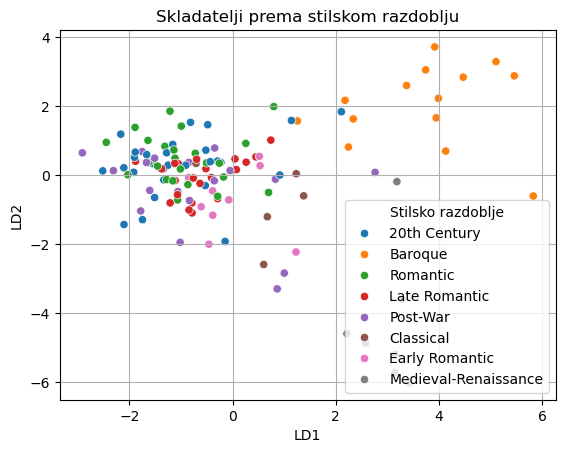

In [99]:
#df za laksu vizualizaciju
lda_df = pd.DataFrame(X_lda[:,:2],  #prve 2 LDA komponente
                      columns=['LD1','LD2'])  #df s ovim imenima stupaca
lda_df['epoch'] = y.values

sns.scatterplot(data=lda_df, x='LD1', y='LD2', hue='epoch') #razl boje po hue
plt.title('Skladatelji prema stilskom razdoblju')
plt.xlabel('LD1')
plt.ylabel('LD2')
plt.legend(title='Stilsko razdoblje')
plt.grid(True)

In [100]:
explained_variance = lda.explained_variance_ratio_
print("Udjeli objašnjene varijance po diskriminanti:")
for i, var in enumerate(explained_variance):
    print(f"LD{i+1}: {var:.4f}")

Udjeli objašnjene varijance po diskriminanti:
LD1: 0.3611
LD2: 0.2322
LD3: 0.1475
LD4: 0.0958
LD5: 0.0658
LD6: 0.0636
LD7: 0.0340


---

<b>c)</b> Ponovite postupak višeklasne <b>linearne diskriminantne analize</b>, ovaj put nad reduciranim skupom podataka koji sadrži samo sljedeća stilska razdoblja:
`
["Baroque", "Classical", "Early Romantic", "Romantic", "Late Romantic"]
`. <br>
<b>Prikažite graf raspršenja</b> koristeći prve dvije diskriminante, gdje jedna točka predstavlja jednog skladatelja.
Različitom bojom prikažite različite klase. <br>
<b>Ispišite</b> udjele objašnjene varijance za sve diskriminante. <br>
Komentirajte kvalitetu dobivenog prikaza u odnosu na prethodni podzadatak.

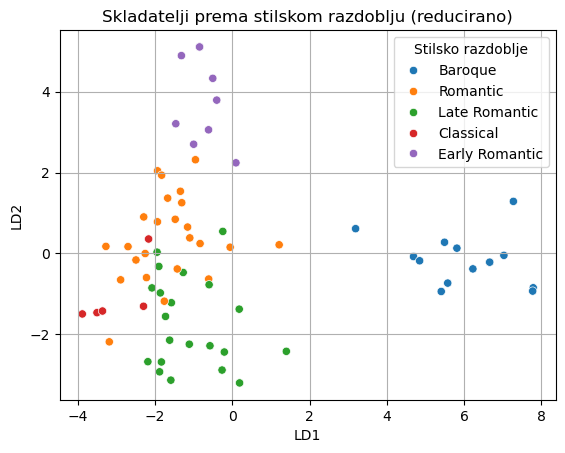

Udjeli objašnjene varijance po diskriminanti (reducirani skup):
LD1: 0.6115
LD2: 0.1909
LD3: 0.1152
LD4: 0.0824

Na prijasnjem grafu broj skladatelja po razdoblju je:
 epoch
20th Century            28
Romantic                24
Late Romantic           21
Post-War                18
Baroque                 14
Early Romantic           9
Medieval-Renaissance     7
Classical                5
Name: count, dtype: int64


A sad
:  epoch
Romantic          24
Late Romantic     21
Baroque           14
Early Romantic     9
Classical          5
Name: count, dtype: int64


In [101]:
#REDUCIRAJ PRIJE TRENIRANJA!!!
reduced = ["Baroque", "Classical", "Early Romantic", "Romantic", "Late Romantic"]
filtered_df = C_std_new[C_std_new['epoch'].isin(reduced)] #zadrzi one koji su u reduced :)

X_reduced = filtered_df.drop('epoch', axis=1)
y_reduced = filtered_df['epoch']

lda_reduced = LinearDiscriminantAnalysis()
X_lda_reduced = lda_reduced.fit_transform(X_reduced, y_reduced)

lda_df_reduced = pd.DataFrame(X_lda_reduced[:, :2], columns=['LD1', 'LD2'])
lda_df_reduced['epoch'] = y_reduced.values

sns.scatterplot(data=lda_df_reduced, x='LD1', y='LD2', hue='epoch')
plt.title('Skladatelji prema stilskom razdoblju (reducirano)')
plt.xlabel('LD1')
plt.ylabel('LD2')
plt.legend(title='Stilsko razdoblje')
plt.grid(True)
plt.show()

explained_variance_reduced = lda_reduced.explained_variance_ratio_
print("Udjeli objašnjene varijance po diskriminanti (reducirani skup):")
for i, var in enumerate(explained_variance_reduced):
    print(f"LD{i+1}: {var:.4f}")

print("\nNa prijasnjem grafu broj skladatelja po razdoblju je:\n", lda_df['epoch'].value_counts()) #koliko skladatelja po razdoblju
print("\n")
print("A sad\n: ", lda_df_reduced['epoch'].value_counts())

## 2. Višedimenzionalno skaliranje

U ovom zadatku želimo vizualizirati sličnosti između pojedinih stilskih razdoblja koristeći metričko i nemetričko skaliranje.

---

<b>a)</b>
**Izračunajte i prikažite** kontingencijsku tablicu za varijable `category` i `epoch` (stilsko razdoblje).
Neka retci sadrže kategorije, a stupci stilska razdoblja.

In [102]:
C = pd.crosstab(df['category'], df['epoch'])
print("Kontingencijska matrica C:\n", C)

Kontingencijska matrica C:
 epoch                          20th Century  Baroque  Classical  \
category                                                          
Ballet                                   19        2          0   
Cello Concerto                            6        0          5   
Cello Sonata                              3        0          0   
Chant                                     1        0          0   
Choral orchestral                         7       42          6   
Clarinet Quintet                          0        0          1   
Clarinet Sonata                           1        0          0   
Double Concerto                           1        1          2   
Flute Sonata                              1        1          0   
Harpsichord conceto                       2        5          0   
Lieder / Song                             8        0          0   
Mass / Requiem                            3        2          4   
Octet                             

---

<b> b)</b> **Izračunajte** udaljenosti među stilskim razdobljima koristeći *totalnu varijacijsku udaljenost*.
Neka je $C$ kontingencijska matrica dimenzija $N \times M$, te neka su kategorije skladbi raspoređene po retcima, a stilska razdoblja po stupcima. Totalna varijacijska daljenost između dva stilska razdboblja $i$ i $j$ računa se kao
$$
\delta_{i,j} = \frac{1}{2} \sum_{k=1}^N \left\lvert \frac{C_{k,i}}{S_i} - \frac{C_{k,j}}{S_j} \right\rvert,
$$
gdje je $S_i = \sum_{k=1}^N C_{k,i}$. **Izračunajte i prikažite** matricu udaljenosti $\Delta$ čiji elementi su $\Delta_{i, j} = \delta_{i, j}$. <br>
Provjerite koji parovi stilskih razdoblja su najsličniji, a koji najrazličitiji.

In [108]:
import numpy as np

#Normalizacija po stupcima (S_i)
S = C.sum(axis=0)  #S_i za svaki stupac
P = C / S          #Proporcije: C_{k,i} / S_i        

#Matrica udaljenosti
epochs = C.columns
M = len(epochs)
delta = np.zeros((M, M))

for i in range(M):
    for j in range(M):
        delta[i, j] = 0.5 * np.sum(np.abs(P.iloc[:, i] - P.iloc[:, j]))

delta_df = pd.DataFrame(delta, index=epochs, columns=epochs)

print("Matrica totalne varijacijske udaljenosti delta:")
delta_df

Matrica totalne varijacijske udaljenosti delta:


epoch,20th Century,Baroque,Classical,Early Romantic,Late Romantic,Medieval-Renaissance,Post-War,Romantic
epoch,,,,,,,,
20th Century,0.000000,0.585714,0.420856,0.454386,0.300816,0.770463,0.261111,0.301483
Baroque,0.585714,0.000000,0.651381,0.631880,0.592972,0.751987,0.616013,0.568025
Classical,0.420856,0.651381,0.000000,0.415740,0.442548,0.800908,0.516751,0.395069
Early Romantic,0.454386,0.631880,0.415740,0.000000,0.357317,0.737632,0.481725,0.308647
Late Romantic,0.300816,0.592972,0.442548,0.357317,0.000000,0.769916,0.377731,0.216492
Medieval-Renaissance,0.770463,0.751987,0.800908,0.737632,0.769916,0.000000,0.731419,0.807192
Post-War,0.261111,0.616013,0.516751,0.481725,0.377731,0.731419,0.000000,0.390255
Romantic,0.301483,0.568025,0.395069,0.308647,0.216492,0.807192,0.390255,0.000000


In [105]:
print("Najrazlicitiji:", np.max(delta))
print("\nNajslicniji:", np.min(delta[np.nonzero(delta)]))

Najrazlicitiji: 0.8071924383399793

Najslicniji: 0.21649168048136547


---

<b>c)</b>
Provedite postupak klasičnog, <b>metričnog višedimenzionalnog skaliranja,</b> koristeći prethodno dobivenu <b>matricu udaljenosti.</b><br>
**Prikažite** kategorije na grafu raspršenja s **dvije dimenzije** i **označite** koju kategoriju pojedina točka predstavlja. 
<b>Ispišite</b> <i>stress</i> vrijedost.<br>
Uočavate li smisleno grupiranje stilskih razdoblja
 prema njihovom povijesnom slijedu?

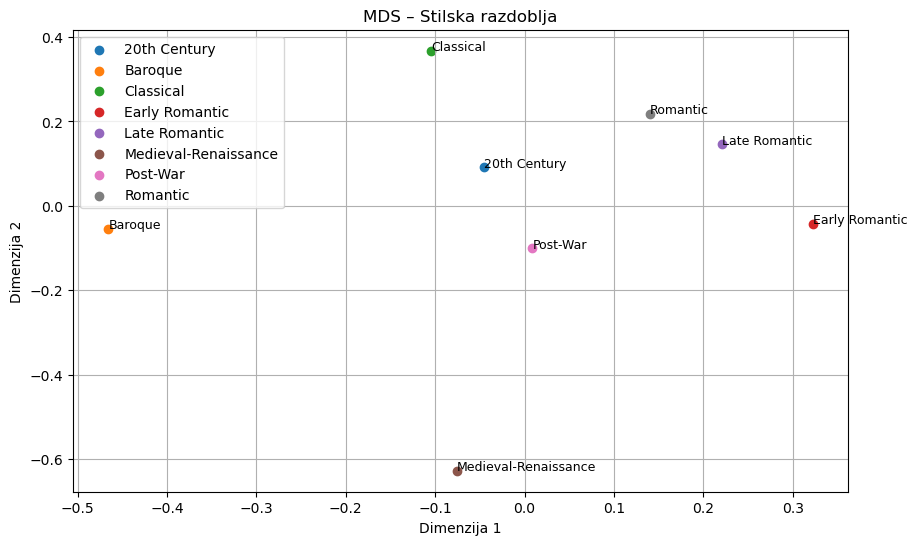

Stress vrijednost: 0.3340


In [109]:
from sklearn.manifold import MDS #metricko visedimenz skal

mds = MDS(n_components=2, #2D prikaz
          dissimilarity='precomputed', random_state=18)
mds_coords = mds.fit_transform(delta_df) 	#razdoblja >> 2D tocke koje sto bolje cuvaju udaljenosti

mds_df = pd.DataFrame(mds_coords, index=delta_df.index, columns=['Dim1', 'Dim2'])

plt.figure(figsize=(10, 6))
for i in mds_df.index:
    plt.scatter(mds_df.loc[i, 'Dim1'], mds_df.loc[i, 'Dim2'], label=i)
    plt.text(mds_df.loc[i, 'Dim1'], mds_df.loc[i, 'Dim2'], i, fontsize=9)

plt.title("MDS – Stilska razdoblja")
plt.xlabel("Dimenzija 1")
plt.ylabel("Dimenzija 2")
plt.grid(True)
plt.legend()
plt.show()

# Stress
print(f"Stress vrijednost: {mds.stress_:.4f}")

--- 

<b>d)</b> Neka je $\mathbf C$ kontingencijska tablica s početka ovog zadatka.
Neka je mjera sličnosti između dvaju stilskih razdoblja $i$ i $j$ definirana na način:
\begin{equation}
\mathit{sim}\left(i, j\right) = \sum_{k = 0}^N \frac{\min \left\{C_{k, i}, C_{k, j} \right\}}{\max \left\{C_{k, i}, C_{k, j}\right\}}
\end{equation}
<b>Izračunajte sličnosti</b> između svih parova stilskih razdoblja. Zatim, sami izvedite neku mjeru različitosti temeljem izračunate mjere sličnosti.
Konačno, <b>izračunajte matricu različitosti</b> koja sadrži različitosti svih parova stilskih razdoblja.<br>
Kako se rezultati razlikuju u odnosu na 2. b)?

In [124]:
epochs = C.columns
M = len(epochs)
sim_matrix = np.zeros((M, M))

for i in range(M):
    for j in range(M):
        sim = 0
        for k in range(C.shape[0]):  # po kategorijama
            a = C.iloc[k, i]
            b = C.iloc[k, j]
            if max(a, b) > 0:
                sim += min(a, b) / max(a, b)
        sim_matrix[i, j] = sim

#Slicnost -> različitost (reciprocno)
div_matrix = 1 / (sim_matrix + 1e-8) 

div_df = pd.DataFrame(div_matrix, index=epochs, columns=epochs)
sim_df = pd.DataFrame(sim_matrix, index=epochs, columns=epochs)

print("Matrica sličnosti:")
sim_df

Matrica sličnosti:


category,Choral orchestral,Lieder / Song,Piano Concerto,Piano Sonata,String Quartet,Symphony,Unsorted Orchestral,Violin Sonata
category,,,,,,,,
Choral orchestral,5.000000,0.312500,1.250000,1.686111,2.000000,0.840909,2.277778,1.888889
Lieder / Song,0.312500,5.000000,1.800000,2.582579,1.409524,2.369444,1.795833,1.262500
Piano Concerto,1.250000,1.800000,6.000000,2.152112,2.285714,2.767677,2.516667,2.300000
Piano Sonata,1.686111,2.582579,2.152112,8.000000,2.486937,2.792054,1.842555,1.342432
String Quartet,2.000000,1.409524,2.285714,2.486937,7.000000,3.430808,2.628571,3.183333
Symphony,0.840909,2.369444,2.767677,2.792054,3.430808,7.000000,2.250000,2.277778
Unsorted Orchestral,2.277778,1.795833,2.516667,1.842555,2.628571,2.250000,7.000000,3.750000
Violin Sonata,1.888889,1.262500,2.300000,1.342432,3.183333,2.277778,3.750000,6.000000


In [125]:
print("\nMatrica različitosti (recipročna mjera):")
div_df


Matrica različitosti (recipročna mjera):


category,Choral orchestral,Lieder / Song,Piano Concerto,Piano Sonata,String Quartet,Symphony,Unsorted Orchestral,Violin Sonata
category,,,,,,,,
Choral orchestral,0.200000,3.200000,0.800000,0.593081,0.500000,1.189189,0.439024,0.529412
Lieder / Song,3.200000,0.200000,0.555556,0.387210,0.709459,0.422040,0.556845,0.792079
Piano Concerto,0.800000,0.555556,0.166667,0.464660,0.437500,0.361314,0.397351,0.434783
Piano Sonata,0.593081,0.387210,0.464660,0.125000,0.402101,0.358159,0.542724,0.744917
String Quartet,0.500000,0.709459,0.437500,0.402101,0.142857,0.291477,0.380435,0.314136
Symphony,1.189189,0.422040,0.361314,0.358159,0.291477,0.142857,0.444444,0.439024
Unsorted Orchestral,0.439024,0.556845,0.397351,0.542724,0.380435,0.444444,0.142857,0.266667
Violin Sonata,0.529412,0.792079,0.434783,0.744917,0.314136,0.439024,0.266667,0.166667


---

<b>e)</b>
Provedite postupak <b>nemetričnog višedimenzionalnog skaliranja,</b> koristeći prethodno dobivenu <b>matricu različitosti.</b> <br>
**Prikažite** kategorije na grafu raspršenja s **dvije dimenzije** i **označite** koju kategoriju pojedina točka predstavlja. 
<b>Ispišite</b> <i>stress</i> vrijedost.<br>
Uočavate li smisleno grupiranje stilskih razdoblja prema njihovom povijesnom slijedu?

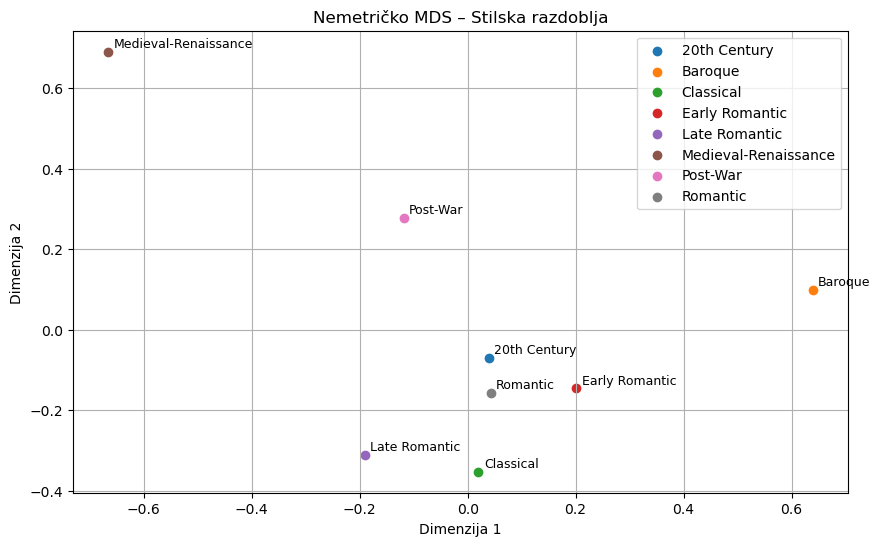

Stress vrijednost (nemetričko MDS): 0.0790


In [51]:
from sklearn.manifold import MDS

nmds = MDS(n_components=2, dissimilarity='precomputed', metric=False, random_state=42)
nmds_coords = nmds.fit_transform(div_df)

nmds_df = pd.DataFrame(nmds_coords, index=div_df.index, columns=['Dim1', 'Dim2'])

# Crtanje
plt.figure(figsize=(10, 6))
for i in nmds_df.index:
    plt.scatter(nmds_df.loc[i, 'Dim1'], nmds_df.loc[i, 'Dim2'], label=i)
    plt.text(nmds_df.loc[i, 'Dim1'] + 0.01, nmds_df.loc[i, 'Dim2'] + 0.01, i, fontsize=9)

plt.title("Nemetričko MDS – Stilska razdoblja")
plt.xlabel("Dimenzija 1")
plt.ylabel("Dimenzija 2")
plt.grid(True)
plt.legend()
plt.show()

print(f"Stress vrijednost (nemetričko MDS): {nmds.stress_:.4f}")

---

## 3. Analiza korespondencije

<b>a) </b>
**Kreirajte** novi podskup podataka tako da sadrži samo skladbe **prvih 5&ndash;10 skladatelja** po nekom kriteriju &mdash; proizvoljno odaberite kriterij po kojemu ćete ih poredati (npr. ukupan broj skladbi, ukupan broj glasova po svim skladbama, prosječan broj glasova po svim skladbama, ili samo odaberite 5&ndash;10 skladatelja po vlastitom izboru).
Zatim **odredite** koje kategorije skladbi se najčešće pojavljuju u dobivenom podskupu, te unutar njega zadržite samo skladbe koje pripadaju otprlike **5&ndash;10 najčešćih kategorija**.

In [110]:
top_composers = df['composer'].value_counts().head(8).index.tolist()

df_top = df[df['composer'].isin(top_composers)]

top_categories = df_top['category'].value_counts().head(8).index.tolist()

df_top_filtered = df_top[df_top['category'].isin(top_categories)] #samo skladbe u top kategorijama

print("Top skladatelji:", top_composers)
print("\nTop kategorije:\n", df_top['category'].value_counts().head(8))

Top skladatelji: ['Ludwig van Beethoven', 'Wolfgang Amadeus Mozart', 'Johann Sebastian Bach', 'Johannes Brahms', 'Franz Schubert', 'Robert Schumann', 'Joseph Haydn', 'Dmitri Shostakovich']

Top kategorije:
 category
Piano Sonata           93
Symphony               66
String Quartet         37
Lieder / Song          27
Piano Concerto         25
Choral orchestral      25
Unsorted Orchestral    20
Violin Sonata          16
Name: count, dtype: int64


---

U nastavku vježbe koristite ovako generirani podskup podataka.

<b>b)</b> **Izračunajte i prikažite** kontingencijsku tablicu između skladatelja i kategorije skladbi koje su napisali.


In [112]:
contingency_table = pd.crosstab(df_top_filtered['composer'], df_top_filtered['category'])

print("Kontingencijska tablica skladatelj × kategorija:")
contingency_table

Kontingencijska tablica skladatelj × kategorija:


category,Choral orchestral,Lieder / Song,Piano Concerto,Piano Sonata,String Quartet,Symphony,Unsorted Orchestral,Violin Sonata
composer,,,,,,,,
Dmitri Shostakovich,0,1,2,1,7,12,3,0
Franz Schubert,1,16,0,12,4,6,1,1
Johann Sebastian Bach,18,0,0,14,0,0,2,1
Johannes Brahms,1,4,2,8,3,4,6,3
Joseph Haydn,2,0,1,5,3,22,0,0
Ludwig van Beethoven,0,1,5,26,15,9,3,4
Robert Schumann,0,5,3,17,1,4,2,1
Wolfgang Amadeus Mozart,3,0,12,10,4,9,3,6


---

<b>c)</b> **Prikažite** graf raspršenja analize korespondencije između varijabli `composer` i `category` koristeći prve dvije komponente. 
Jasno <b>označite</b> (bojom i oblikom markera, ili natpisima) kojeg skladatelja, odnosno kategoriju, predstavlja pojedina točka.
<b>Ispišite</b> udjele objašnjene varijance za sve komponente, te ukupnu inerciju.
Također, na grafu <b>označite ishodište</b> radi lakše interpretacije. <br>
Obratite pozornost na objašnjenu varijancu temeljem prve dvije komponente. Na temelju dobivenog grafa i kontingencijske tablice iz prethodnog zadatka pokušajte odgovoriti na sljedeća pitanja:

-   Koji skladatelji se najviše izdvajaju po pojedinoj kategoriji?
-   Koji skladatelji su određenu kategoriju skladbi pisali znatno više ili manje u usporedbi s drugim skladateljima?
-   Koji skladatelji su određenu kategoriju skladbi pisali znatno više ili manje u usporedbi s drugim kategorijama?
-   Koji skladatelji su pisali prosječan broj skladbi u svim kategorijama?

C:\Users\Home\AppData\Local\Temp\ipykernel_47032\130956228.py:13: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.annotate(txt, (row_coords[0][i]+0.01, row_coords[1][i]+0.01), color='red')
C:\Users\Home\AppData\Local\Temp\ipykernel_47032\130956228.py:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.annotate(txt, (col_coords[0][i]+0.01, col_coords[1][i]+0.01), color='blue')


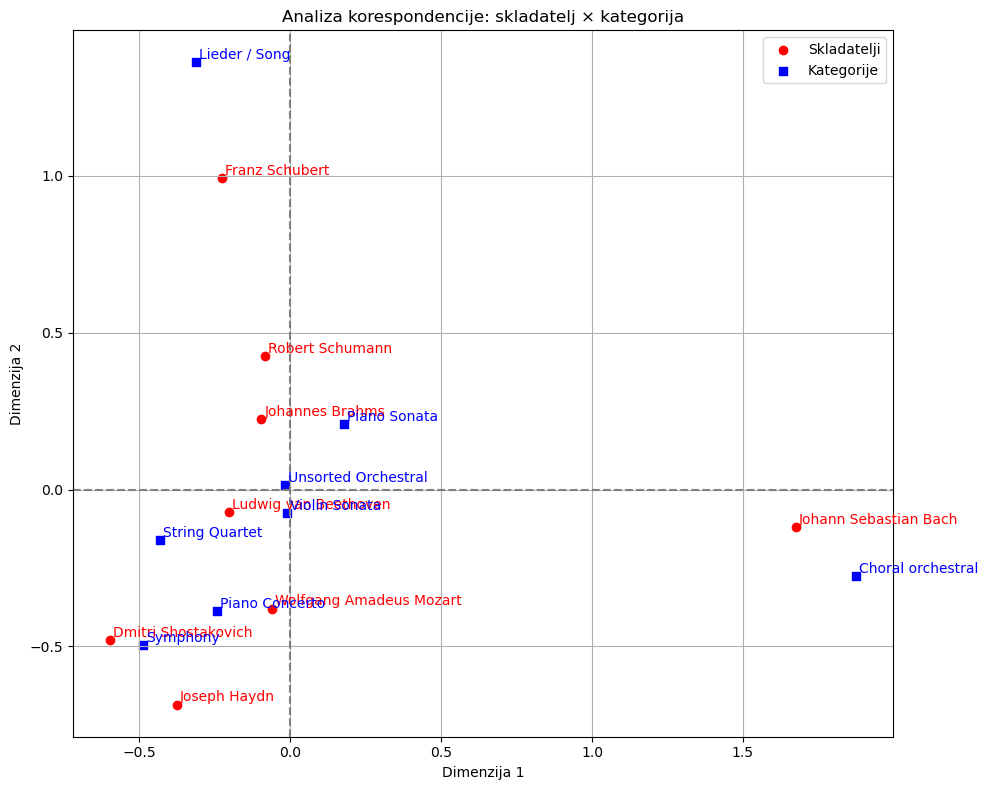

In [119]:
ca = prince.CA(n_components=2, random_state=42)
ca = ca.fit(contingency_table)

row_coords = ca.row_coordinates(contingency_table)
col_coords = ca.column_coordinates(contingency_table)

plt.figure(figsize=(10, 8))
plt.axhline(0, color='gray', linestyle='--')  # Ishodište x
plt.axvline(0, color='gray', linestyle='--')  # Ishodište y

plt.scatter(row_coords[0], row_coords[1], c='red', label='Skladatelji', marker='o')
for i, txt in enumerate(contingency_table.index):
    plt.annotate(txt, (row_coords[0][i]+0.01, row_coords[1][i]+0.01), color='red')

plt.scatter(col_coords[0], col_coords[1], c='blue', label='Kategorije', marker='s')
for i, txt in enumerate(contingency_table.columns):
    plt.annotate(txt, (col_coords[0][i]+0.01, col_coords[1][i]+0.01), color='blue')

plt.title('Analiza korespondencije: skladatelj × kategorija')
plt.xlabel('Dimenzija 1')
plt.ylabel('Dimenzija 2')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [120]:
eigenvalues = ca.eigenvalues_
explained = eigenvalues / eigenvalues.sum()

print("Udjeli objašnjene varijance po dimenzijama:")
for i, inertia in enumerate(explained):
    print(f"Dimenzija {i+1}: {inertia:.4f}")

print(f"\nUkupna inercija: {explained.sum():.4f}")

Udjeli objašnjene varijance po dimenzijama:
Dimenzija 1: 0.6041
Dimenzija 2: 0.3959

Ukupna inercija: 1.0000


---

<b>d)</b> <b>Provedite analizu korespondencije</b> između varijabli `country` i `epoch`.
U obzir uzmite <b>reducirani skup podataka</b> koji sadrži samo sljedeće države: `["Germany", "Austria", "Italy", "France", "Hungary", "Russia", "United States"]`.
<b>Prikažite graf</b> kao i u prethodnom podzadatku, te <b>ispišite</b> udjele objašnjene varijance i ukupnu inerciju.
Što možete zaključiti o odnosima država i stilskih razdoblja pomoću grafa?

C:\Users\Home\AppData\Local\Temp\ipykernel_47032\4050608176.py:17: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.annotate(txt, (row_coords[0][i]+0.01, row_coords[1][i]+0.01), color='red')
C:\Users\Home\AppData\Local\Temp\ipykernel_47032\4050608176.py:21: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.annotate(txt, (col_coords[0][i]+0.01, col_coords[1][i]+0.01), color='blue')


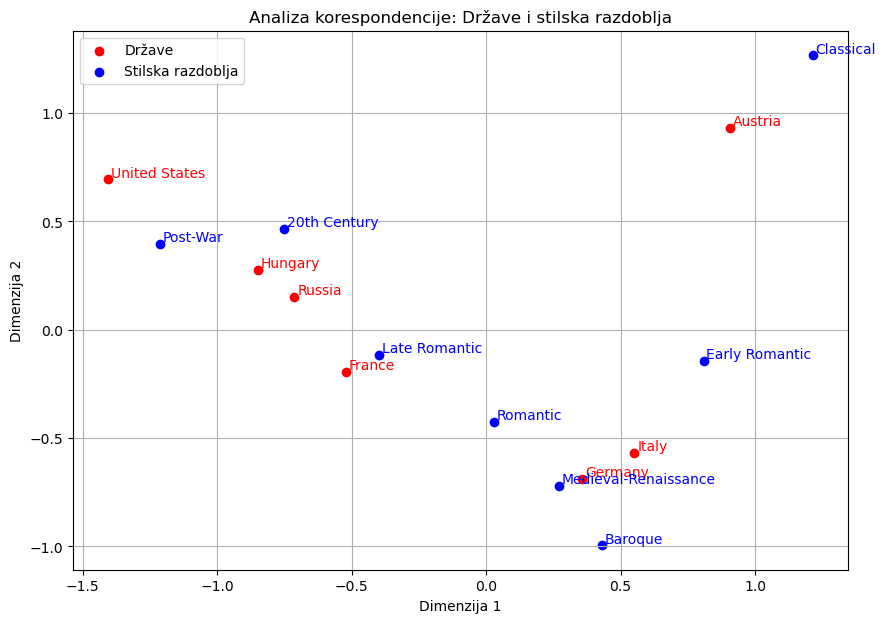

In [121]:
import prince
selected_countries = ["Germany", "Austria", "Italy", "France", "Hungary", "Russia", "United States"]
df_reduced = df[df['country'].isin(selected_countries)]

C_country_epoch = pd.crosstab(df_reduced['country'], df_reduced['epoch'])

ca = prince.CA(n_components=2, random_state=42)
ca = ca.fit(C_country_epoch)

row_coords = ca.row_coordinates(C_country_epoch)  
col_coords = ca.column_coordinates(C_country_epoch)  

plt.figure(figsize=(10, 7))

plt.scatter(row_coords[0], row_coords[1], c='red', label='Države')
for i, txt in enumerate(C_country_epoch.index):
    plt.annotate(txt, (row_coords[0][i]+0.01, row_coords[1][i]+0.01), color='red')

plt.scatter(col_coords[0], col_coords[1], c='blue', label='Stilska razdoblja')
for i, txt in enumerate(C_country_epoch.columns):
    plt.annotate(txt, (col_coords[0][i]+0.01, col_coords[1][i]+0.01), color='blue')

plt.title('Analiza korespondencije: Države i stilska razdoblja')
plt.xlabel('Dimenzija 1')
plt.ylabel('Dimenzija 2')
plt.grid(True)
plt.legend()
plt.show()

In [122]:
eigenvalues = ca.eigenvalues_
explained = eigenvalues / eigenvalues.sum()

print("Udjeli objašnjene varijance po dimenzijama:")
for i, inertia in enumerate(explained):
    print(f"Dimenzija {i+1}: {inertia:.4f}")

print(f"\nUkupna inercija: {explained.sum():.4f}")

Udjeli objašnjene varijance po dimenzijama:
Dimenzija 1: 0.5734
Dimenzija 2: 0.4266

Ukupna inercija: 1.0000
